# Лабораторная работа №1: Линейная регрессия и метод главных компонент (PCA)

**Вариант 5. Прогноз продаж продуктов в магазине (Sales Forecasting Dataset)**

## 1. Введение

**Цель работы** — изучить основы линейной регрессии, построить модели Linear Regression, Ridge и Lasso на данных о продажах товаров в магазинах, оценить их качество и сравнить результаты до и после снижения размерности методом главных компонент (PCA).

**Задачи:**
1. Загрузить датасет и провести первичный анализ (структура, пропуски, распределения).
2. Визуализировать распределения признаков и целевой переменной, проверить зависимость цели от признаков (графики, корреляционная матрица).
3. Выполнить предобработку: обработка пропусков, кодирование категориальных признаков, стандартизация, разделение на train/test (80/20).
4. Оценить мультиколлинеарность с помощью VIF.
5. Обучить Linear Regression, Ridge и Lasso с кросс-валидацией; рассчитать RMSE, $R^2$, MAPE.
6. Построить графики остатков (с линией на уровне 0) и оценить гомо-/гетероскедастичность.
7. Применить PCA после стандартизации (порог 95% дисперсии) и повторить моделирование на главных компонентах.
8. Сравнить метрики до и после PCA и сформулировать выводы.

В работе используются линейная регрессия (МНК), Ridge ($L_2$-регуляризация), Lasso ($L_1$-регуляризация), пятикратная кросс-валидация и конвейеры `Pipeline` для защиты от утечки данных.

**Запуск:** нужен Python 3.9+ и библиотеки `numpy`, `pandas`, `matplotlib`, `scikit-learn` (в Google Colab они уже есть). Рядом с ноутбуком должны лежать два файла: `Test-Set.csv` и `Submission.csv`; в Colab ноутбук сам предложит их загрузить.

### Установка библиотек (нужна только на чистом компьютере)

In [ ]:
%pip install -q numpy pandas matplotlib scikit-learn

## 2. Описание датасета

Используется набор **Big Mart Sales** (задача «Big Mart Sales III»): продажи товаров в 10 магазинах сети в разных городах, 2013 год. Данные состоят из двух файлов с одинаковым порядком строк (5681 наблюдение):

- `Test-Set.csv` — признаки товара и магазина (11 столбцов);
- `Submission.csv` — столбец `Item_Outlet_Sales` (продажи товара в магазине) с идентификаторами товара и магазина.

Строки файлов объединяются по порядку, а совпадение идентификаторов проверяется в коде (`assert`). Целевая переменная `Item_Outlet_Sales` непрерывная, поэтому решается задача **регрессии** (логистическая регрессия не требуется).

> **Важное замечание об источнике целевой переменной.** Столбец продаж взят из файла `Submission.csv`, то есть это значения продаж для тестовых строк набора, выданные в виде файла-ответа, а не проверенные фактические продажи из обучающего файла. Поэтому метрики качества ниже показывают, насколько хорошо линейная модель восстанавливает эти значения по признакам. Для работы на «чистых» фактических продажах достаточно подставить обучающий файл набора (Train) — код и структура отчёта не изменятся.

| Переменная | Тип | Описание |
|:---|:---|:---|
| `ProductID` | идентификатор | код товара (в модель не входит) |
| `Weight` | числовая | вес товара |
| `FatContent` | категориальная | жирность (Low Fat / Regular) |
| `ProductVisibility` | числовая | доля площади выкладки магазина, отведённая товару |
| `ProductType` | категориальная | категория товара (16 значений) |
| `MRP` | числовая | максимальная розничная цена товара |
| `OutletID` | идентификатор | код магазина (в модель не входит) |
| `EstablishmentYear` | числовая | год открытия магазина |
| `OutletSize` | категориальная | размер магазина (Small / Medium / High) |
| `LocationType` | категориальная | тип города (Tier 1–3) |
| `OutletType` | категориальная | тип магазина (Grocery Store, Supermarket Type 1–3) |
| `Item_Outlet_Sales` | числовая | **продажи товара в магазине (target)** |

Идентификаторы `ProductID` и `OutletID` в модель не включаются: у них слишком много уникальных значений, а свойства магазина и так описаны остальными признаками.

### 2.1. Импорт библиотек

In [ ]:
from __future__ import annotations
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

RANDOM_STATE = 42
TARGET = "Item_Outlet_Sales"
NUMERIC_FEATURES = ["Weight", "ProductVisibility", "MRP", "EstablishmentYear"]
CATEGORICAL_FEATURES = ["FatContent", "ProductType", "OutletSize", "LocationType", "OutletType"]
FEATURES_FILE = "Test-Set.csv"      # признаки товаров и магазинов (Big Mart)
SALES_FILE = "Submission.csv"       # значения Item_Outlet_Sales для этих же строк
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Библиотеки загружены.")

Импортированы `pandas`, `numpy`, `matplotlib`, `scikit-learn`. Заданы константы, имена файлов и каталог для сохранения графиков.

### 2.2. Загрузка и первичный просмотр

In [ ]:
def find_file(name: str) -> Path | None:
    for p in (Path(name), Path("data") / name, Path("/content") / name):
        if p.exists():
            return p
    return None


missing = [n for n in (FEATURES_FILE, SALES_FILE) if find_file(n) is None]
if missing:  # в Colab предлагаем загрузить файлы вручную
    try:
        from google.colab import files
        print("Загрузите файлы:", missing)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Положите файлы {missing} рядом с ноутбуком")

features = pd.read_csv(find_file(FEATURES_FILE))
sales = pd.read_csv(find_file(SALES_FILE))

# строки двух файлов идут в одном порядке: проверяем совпадение идентификаторов
assert (features["ProductID"].values == sales["Item_Identifier"].values).all()
assert (features["OutletID"].values == sales["Outlet_Identifier"].values).all()
df = features.assign(**{TARGET: sales[TARGET].values})

print("Форма:", df.shape)
print("\nТипы:\n", df.dtypes)
print("\nПропуски:\n", df.isna().sum())
display(df.head())
display(df.describe())
for col in CATEGORICAL_FEATURES:
    print(f"\n{col}:\n", df[col].value_counts(dropna=False))

Объединённый датасет содержит 5681 строк и 12 столбцов. Пропуски есть в двух признаках: `Weight` — 976, `OutletSize` — 1606; остальные столбцы заполнены полностью. Признак `FatContent` записан непоследовательно (`Low Fat`, `LF`, `low fat`, `Regular`, `reg`), а у 353 товаров видимость равна 0, что для выставленного на полке товара невозможно. В целевой переменной среднее ≈ 2178, медиана ≈ 1954, минимум ≈ -100 (есть отрицательные значения: 68 строк), максимум ≈ 5960.

### 2.3. Очистка данных

In [ ]:
df_clean = df.copy()

# 1. Приводим к единому виду написания жирности (LF / low fat / reg)
df_clean["FatContent"] = df_clean["FatContent"].replace(
    {"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"}
)
# 2. Нулевая видимость товара на полке невозможна -> считаем пропуском
n_zero_vis = int((df_clean["ProductVisibility"] == 0).sum())
df_clean["ProductVisibility"] = df_clean["ProductVisibility"].replace(0, np.nan)
# 3. Продажи не могут быть отрицательными/нулевыми: такие строки удаляем
n_bad_target = int((df_clean[TARGET] <= 0).sum())
df_clean = df_clean[df_clean[TARGET] > 0].reset_index(drop=True)

print("FatContent после очистки:\n", df_clean["FatContent"].value_counts())
print(f"\nНулевая видимость заменена на пропуск: {n_zero_vis} строк")
print(f"Удалено строк с продажами <= 0: {n_bad_target}")
print(f"Осталось наблюдений: {len(df_clean)} (было {len(df)})")

Выполнены три действия: написания жирности сведены к двум значениям (`Low Fat`, `Regular`); нулевая видимость товара заменена на пропуск (затем он будет заполнен медианой); удалены 68 строк с неположительными продажами — продажи не бывают отрицательными, а нулевые значения сделали бы невозможным расчёт MAPE. Осталось **5613** наблюдений.

### 2.4. Распределения признаков и целевой переменной

In [ ]:
for col in NUMERIC_FEATURES + [TARGET]:
    plt.figure(figsize=(7, 5))
    plt.hist(df_clean[col].dropna(), bins=25, edgecolor="black", alpha=0.75, color="steelblue")
    plt.xlabel(col)
    plt.ylabel("Частота")
    plt.title(f"Distribution: {col}")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"distribution_{col}.png", dpi=110, bbox_inches="tight")
    plt.show()

plt.figure(figsize=(9, 5))
labels = sorted(df_clean["OutletType"].unique())
groups = [df_clean.loc[df_clean["OutletType"] == t, TARGET].values for t in labels]
plt.boxplot(groups)
plt.xticks(range(1, len(labels) + 1), labels, rotation=10)
plt.xlabel("OutletType")
plt.ylabel(TARGET)
plt.title("Sales by outlet type")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "sales_by_outlet_type.png", dpi=110, bbox_inches="tight")
plt.show()

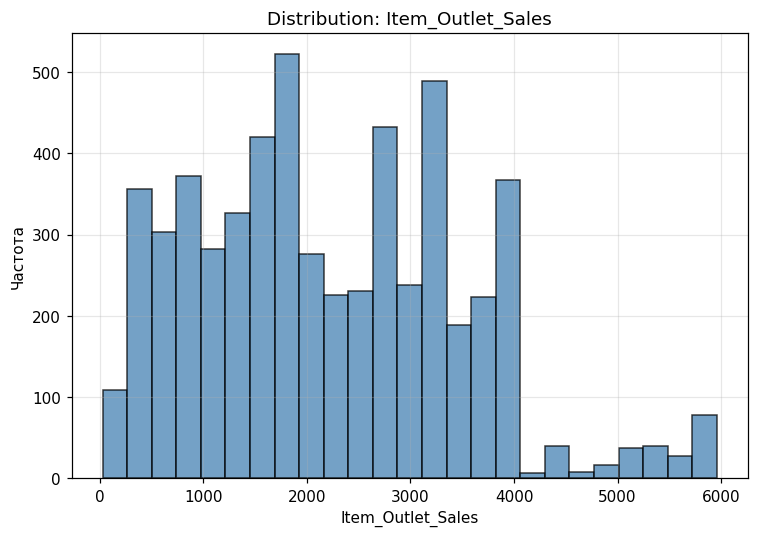

*Рисунок 1. Распределение продаж (Item_Outlet_Sales)*

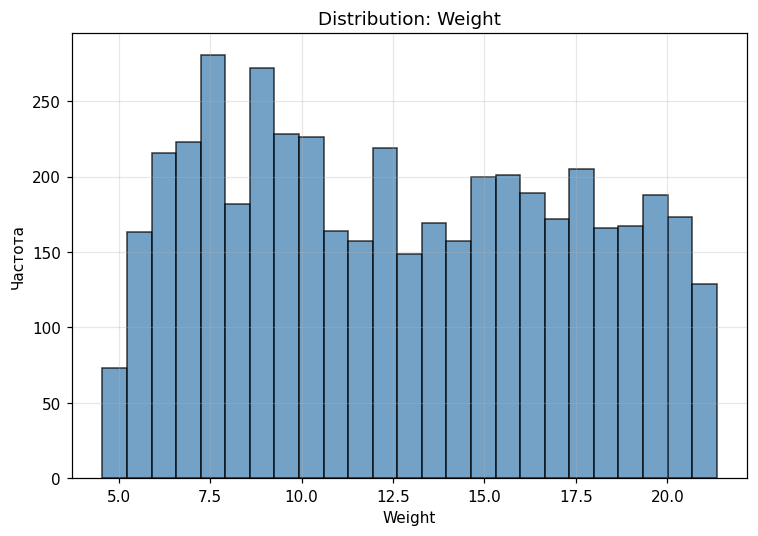

*Рисунок 2. Распределение веса товара*

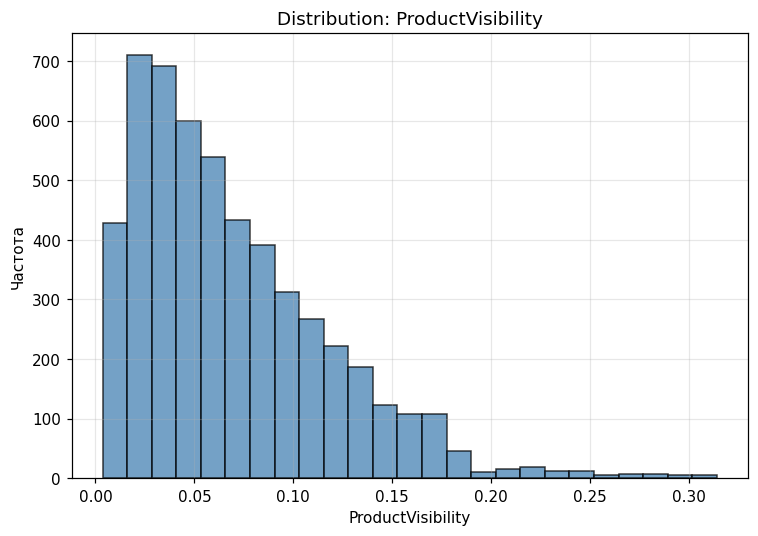

*Рисунок 3. Распределение видимости товара*

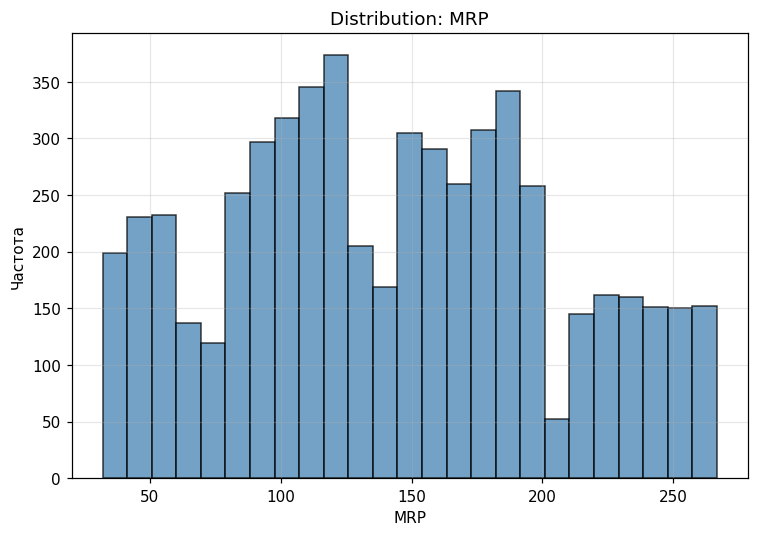

*Рисунок 4. Распределение цены (MRP)*

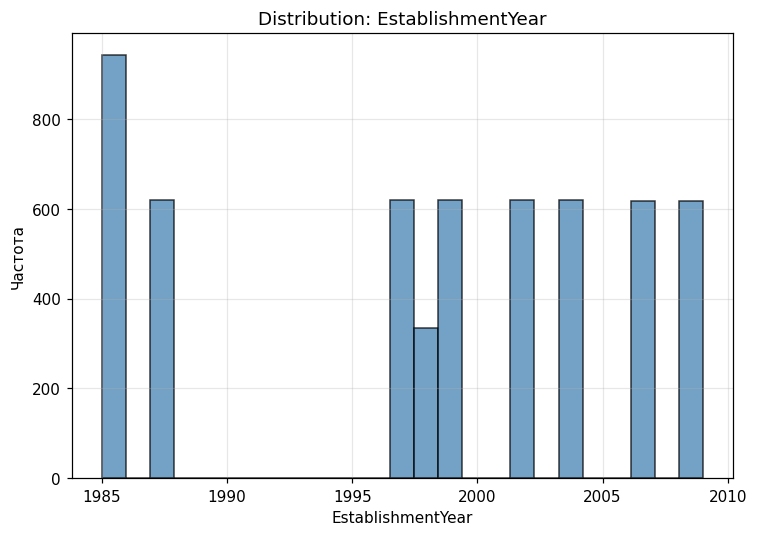

*Рисунок 5. Распределение года открытия магазина*

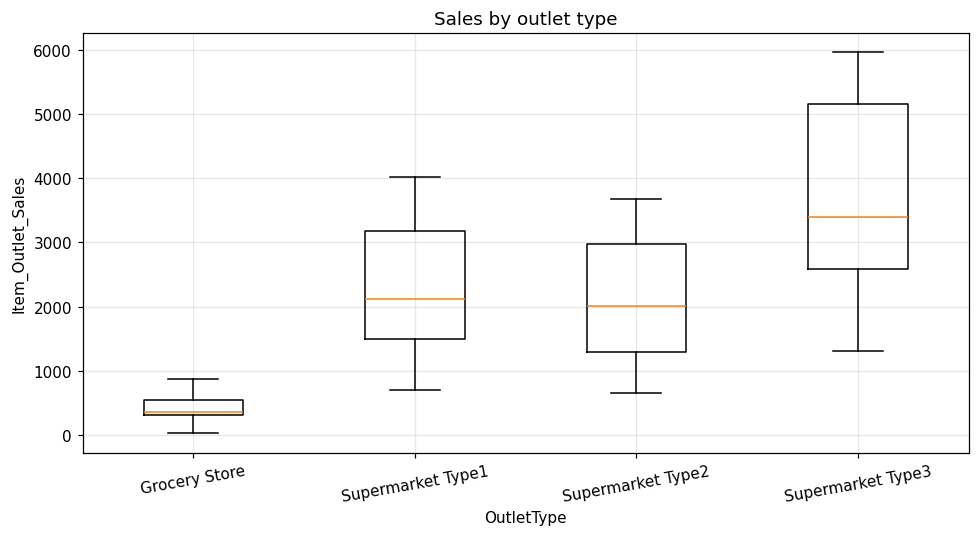

*Рисунок 6. Продажи по типам магазинов*

Продажи имеют умеренную правостороннюю асимметрию (коэффициент ≈ 0.49): большинство строк с небольшими и средними продажами и хвост крупных. `ProductVisibility` сильнее всего скошена вправо (≈ 1.26); `Weight` распределён симметрично, а `MRP` имеет несколько пиков — ценовые группы товаров (около 50, 110 и 150–190). `EstablishmentYear` принимает всего 9 дискретных значений — по числу различных лет открытия магазинов. Boxplot показывает главное различие: средние продажи — Supermarket Type3 ≈ 3720, Supermarket Type1 ≈ 2287, Supermarket Type2 ≈ 2081, Grocery Store ≈ 410. Тип магазина — очень информативный категориальный предиктор.

### 2.5. Связь продаж с признаками

In [ ]:
for col in ["MRP", "ProductVisibility", "Weight"]:
    plt.figure(figsize=(7, 5))
    for outlet_type in sorted(df_clean["OutletType"].unique()):
        subset = df_clean[df_clean["OutletType"] == outlet_type]
        plt.scatter(subset[col], subset[TARGET], label=outlet_type, alpha=0.5, s=12)
    plt.xlabel(col)
    plt.ylabel(TARGET)
    plt.title(f"Sales vs {col}")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"scatter_sales_vs_{col}.png", dpi=110, bbox_inches="tight")
    plt.show()

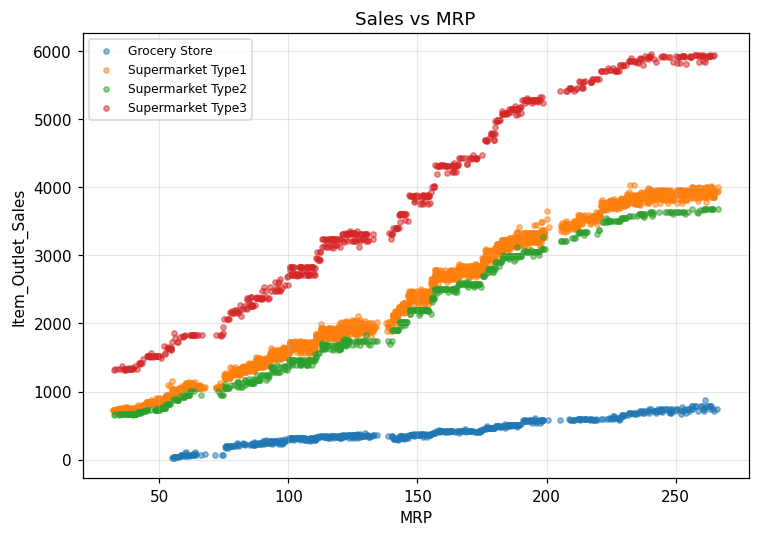

*Рисунок 7. Продажи vs цена (MRP)*

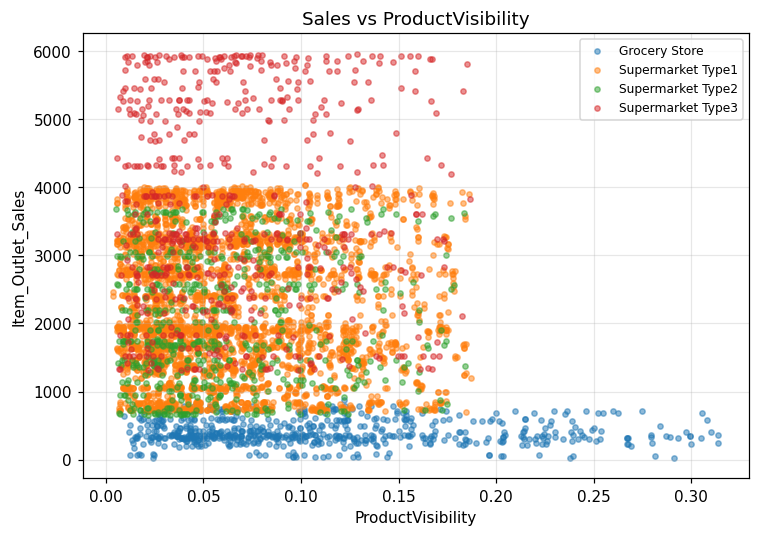

*Рисунок 8. Продажи vs видимость товара*

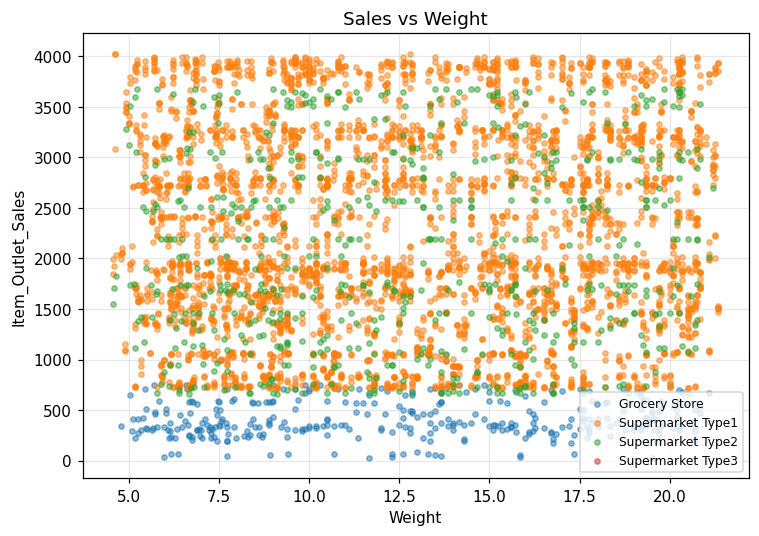

*Рисунок 9. Продажи vs вес товара*

- **Цена (MRP)** — самая сильная положительная связь (r ≈ 0.71); наклон зависимости зависит от типа магазина: в Grocery Store продажи низкие при любой цене, в Supermarket Type 3 растут быстрее всего.
- **Видимость товара** — слабая отрицательная связь (r ≈ -0.15); вероятно, это отражение типа магазина: в Grocery Store средняя доля выкладки на товар выше (≈ 0.110 против ≈ 0.064 в Supermarket Type 1), а продажи ниже.
- **Вес** — практически нет связи (r ≈ 0.04).

Точки на графиках разделены на группы по типу магазина, поэтому одних числовых признаков для модели недостаточно. Зависимость от цены не линейная: она ступенчатая и выходит на плато при высоких ценах (MRP > 230). Такая «лестница» типична для значений, выданных моделью на решающих деревьях; это согласуется с замечанием из раздела 2 о том, что целевой столбец взят из файла-ответа, а не из фактических продаж.

### 2.6. Корреляционная матрица

In [ ]:
corr = df_clean[NUMERIC_FEATURES + [TARGET]].corr()
display(corr.round(4))
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap="RdYlGn", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=10)
ax.grid(False)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_matrix.png", dpi=110, bbox_inches="tight")
plt.show()

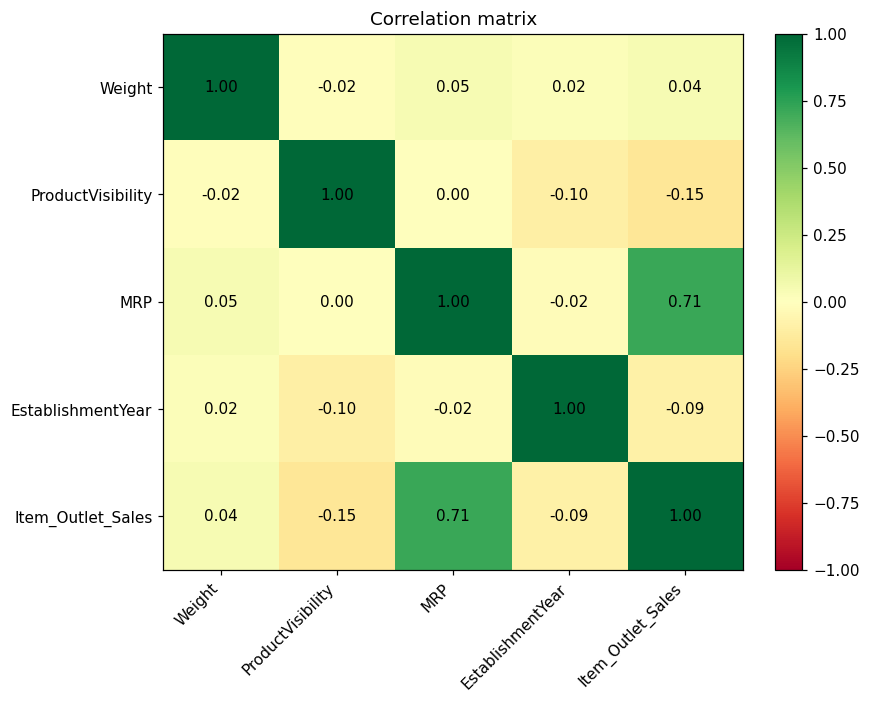

*Рисунок 10. Корреляционная матрица числовых признаков*

**Корреляции с target:** `MRP` ≈ 0.71, `ProductVisibility` ≈ -0.15, `EstablishmentYear` ≈ -0.09, `Weight` ≈ 0.04.

Между самими числовыми признаками корреляции малы (по модулю не больше 0.10), то есть среди числовых признаков мультиколлинеарности нет. Остаётся проверить её с учётом категориальных признаков (раздел 4.1).

## 3. Подготовка данных

Процедуры предобработки (очистка описана в разделе 2.3):

1. **Признаки и цель.** В модель входят 4 числовых и 5 категориальных признака; идентификаторы товара и магазина исключены.
2. **Числовые признаки.** Пропуски заполняются **медианой** (`SimpleImputer(strategy="median")`), затем применяется **стандартизация** (`StandardScaler`) — приведение к нулевому среднему и единичной дисперсии. Масштабы признаков сильно различаются (год ≈ 2000, видимость ≈ 0.06), а Ridge и Lasso чувствительны к масштабу.
3. **Категориальные признаки.** Пропуски заполняются **наиболее частым значением** (`SimpleImputer(strategy="most_frequent")`), затем **one-hot кодирование** (`OneHotEncoder(drop="first", handle_unknown="ignore")`) — первая категория исключается, чтобы не создавать идеальную линейную зависимость dummy-переменных.
4. **Разделение выборки.** `train_test_split(test_size=0.20, random_state=42)` — 80% train, 20% test.
5. **Защита от утечки данных.** Все преобразования входят в `Pipeline` / `ColumnTransformer` и обучаются только на train (и на фолдах CV), тестовая выборка не участвует в подгонке импутеров и скейлеров.

In [ ]:
X = df_clean[NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
y = df_clean[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

def build_model_preprocessor() -> ColumnTransformer:
    """Числовые: median + StandardScaler; категориальные: mode + OneHot(drop first)."""
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, NUMERIC_FEATURES),
            ("cat", categorical_pipe, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        sparse_threshold=0,
    )

def build_pca_preprocessor() -> Pipeline:
    """Для PCA: импутация + one-hot, затем StandardScaler на всей матрице."""
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    ct = ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, NUMERIC_FEATURES),
            ("cat", categorical_pipe, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        sparse_threshold=0,
    )
    return Pipeline([("columns", ct), ("scaler", StandardScaler())])

model_preprocessor = build_model_preprocessor()
pca_preprocessor = build_pca_preprocessor()
print("Препроцессоры созданы.")

Препроцессоры оформлены как `ColumnTransformer`/`Pipeline` и будут использоваться внутри `GridSearchCV`, чтобы медианы, моды и параметры масштабирования считались только по обучающей части каждого фолда. После one-hot кодирования получается 27 признаков (4 числовых и 23 бинарных).

## 4. Ход работы

### 4.1. Анализ мультиколлинеарности (VIF)

Для каждого признака строится вспомогательная регрессия на остальные:

$$VIF_j = \frac{1}{1 - R_j^2}.$$

Чем выше VIF, тем сильнее признак линейно объясняется другими. Часто используют пороги 5 или 10. VIF считается **только по train**, сначала для числовых признаков, затем для всей матрицы (числовые + one-hot). Функция `calc_vif` реализует формулу напрямую через `LinearRegression`.

In [ ]:
def calc_vif(frame: pd.DataFrame) -> pd.DataFrame:
    """VIF_j = 1 / (1 - R_j^2): R_j^2 - детерминация регрессии признака j на все остальные."""
    rows = []
    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        rows.append({"Feature": col, "VIF": 1.0 / max(1.0 - r2, 1e-12)})
    return pd.DataFrame(rows)

# (а) только числовые признаки (после импутации медианой), только train
X_num = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train[NUMERIC_FEATURES]),
    columns=NUMERIC_FEATURES,
)
vif_num = calc_vif(X_num)
print("VIF числовых признаков:")
display(vif_num.round(3))

# (б) вся матрица признаков: числовые + one-hot категориальные
vif_prep = build_pca_preprocessor().fit(X_train)
X_design = pd.DataFrame(
    vif_prep.transform(X_train),
    columns=[n.split("__", 1)[1] for n in vif_prep.named_steps["columns"].get_feature_names_out()],
)
vif_df = calc_vif(X_design).sort_values("VIF", ascending=False).reset_index(drop=True)
print("VIF всей матрицы признаков (топ-12):")
display(vif_df.head(12).round(3))

plt.figure(figsize=(8, 8))
plot_df = vif_df.sort_values("VIF")
plt.barh(plot_df["Feature"], plot_df["VIF"], color="steelblue")
plt.xlabel("VIF")
plt.title("Variance Inflation Factor (VIF), вся матрица признаков")
plt.axvline(10, color="red", linestyle="--", label="порог 10")
plt.axvline(5, color="orange", linestyle="--", label="порог 5")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "vif.png", dpi=110, bbox_inches="tight")
plt.show()

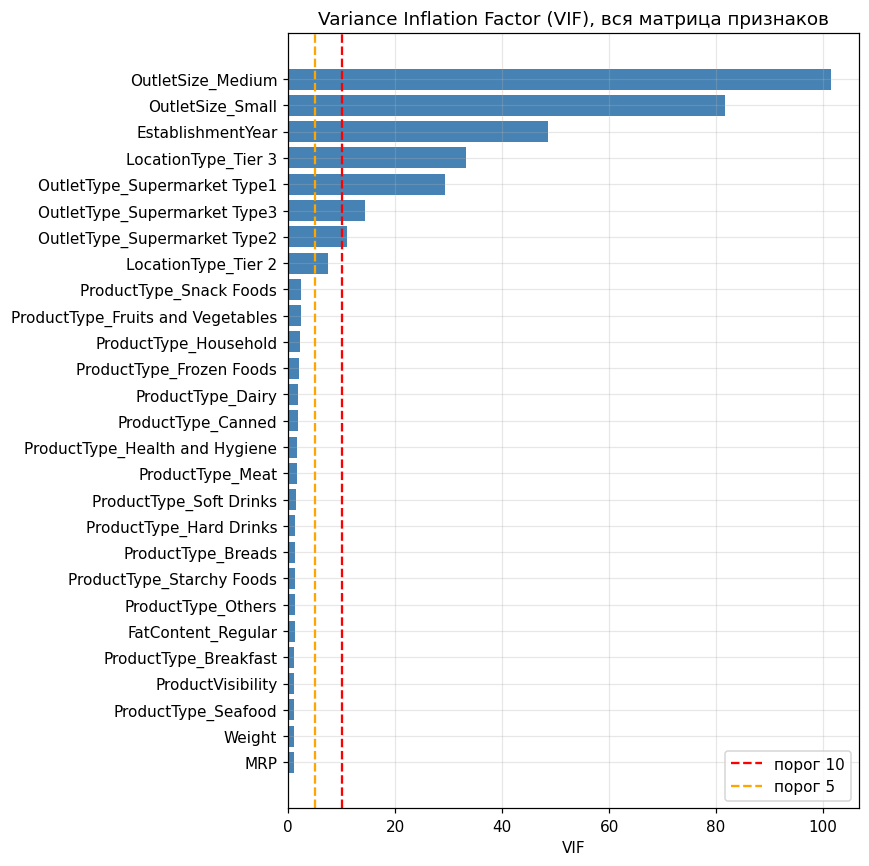

*Рисунок 11. VIF всей матрицы признаков*

**Числовые признаки:** все VIF ≈ 1 (максимум 1.01) — мультиколлинеарности нет.

**Вся матрица признаков:** выше порога 10 оказались 7 признаков: `OutletSize_Medium` ≈ 102, `OutletSize_Small` ≈ 82, `EstablishmentYear` ≈ 49, `LocationType_Tier 3` ≈ 33, `OutletType_Supermarket Type1` ≈ 29, `OutletType_Supermarket Type3` ≈ 14, `OutletType_Supermarket Type2` ≈ 11. Причина — структура данных: магазинов всего 10, и каждый из них имеет один размер, один тип города, один тип и один год открытия. Поэтому эти четыре признака описывают одно и то же — «какой это магазин» — и сильно дублируют друг друга. **Мультиколлинеарность подтверждена**; PCA рассматривается как способ получить ортогональные компоненты.

### 4.2. Регрессионные модели до PCA

Обучаются три модели:

- **Linear Regression** — обычный МНК, минимизирует сумму квадратов остатков, без регуляризации.
- **Ridge** — $L_2$-штраф на квадраты коэффициентов; параметр `alpha` подбирается по сетке `np.logspace(-3, 3, 13)`.
- **Lasso** — $L_1$-штраф (может обнулять коэффициенты); `alpha` из `np.logspace(-3, 1, 12)`, `max_iter=100000`.

Подбор гиперпараметров: `GridSearchCV` с `KFold(n_splits=5, shuffle=True, random_state=42)`, критерий `neg_root_mean_squared_error`.

Метрики на тесте:

$$
RMSE = \sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2},\quad
R^2 = 1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2},\quad
MAPE = \frac{100\%}{n}\sum\left|\frac{y_i-\hat y_i}{y_i}\right|.
$$

In [ ]:
def mape(y_true, y_pred) -> float:
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    non_zero = y_true != 0
    return float(np.mean(np.abs((y_true[non_zero] - y_pred[non_zero]) / y_true[non_zero])) * 100)

def regression_metrics(y_true, y_pred) -> dict:
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "MAPE_%": mape(y_true, y_pred),
    }

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_specs = {
    "LinearRegression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-3, 3, 13)}),
    "Lasso": (Lasso(max_iter=100_000), {"model__alpha": np.logspace(-3, 1, 12)}),
}

searches_before, preds_before, rows_before = {}, {}, []
for name, (est, params) in model_specs.items():
    pipe = Pipeline([
        ("preprocessor", clone(model_preprocessor)),
        ("model", est),
    ])
    gs = GridSearchCV(pipe, params, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    pred = gs.predict(X_test)
    searches_before[name] = gs
    preds_before[name] = pred
    m = regression_metrics(y_test, pred)
    rows_before.append({
        "Model": name, **m,
        "Best_CV_RMSE": float(-gs.best_score_),
        "Best_Params": str(gs.best_params_),
    })

before_results = pd.DataFrame(rows_before)
print("Результаты ДО PCA (тест):")
display(before_results[["Model", "RMSE", "R2", "MAPE_%", "Best_CV_RMSE", "Best_Params"]].round(4))

**Результаты до PCA (тестовая выборка):**

| Model | RMSE | R² | MAPE_% | Best_CV_RMSE |
|:---|---:|---:|---:|---:|
| LinearRegression | ≈ 315.4 | ≈ 0.9372 | ≈ 35.9 | ≈ 310.8 |
| Ridge | ≈ 315.5 | ≈ 0.9372 | ≈ 35.8 | ≈ 310.8 |
| Lasso | ≈ 316.0 | ≈ 0.9370 | ≈ 35.9 | ≈ 310.8 |

Три модели дают практически одинаковое качество (RMSE различается меньше чем на 1 единиц при среднем уровне продаж ≈ 2205). Модель объясняет около 94% дисперсии продаж. Относительная ошибка MAPE ≈ 36% заметно выше, чем можно было бы ожидать при таком $R^2$: MAPE делит ошибку на фактическое значение, а в магазинах типа Grocery Store продажи малы (десятки–сотни), поэтому даже небольшая абсолютная ошибка даёт большую относительную. Регуляризация почти не меняет результат: выборка велика (4490 строк) относительно числа признаков.

### 4.3. Анализ остатков (до PCA)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, pred) in zip(axes, preds_before.items()):
    residuals = y_test.values - pred
    ax.scatter(pred, residuals, alpha=0.5, s=14, edgecolors="none", color="steelblue")
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_xlabel("Предсказанные значения")
    ax.set_ylabel("Остатки (y − ŷ)")
    ax.set_title(f"Остатки: {name}")
plt.suptitle("Графики остатков до PCA (тестовая выборка)", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "residuals_before_pca.png", dpi=110, bbox_inches="tight")
plt.show()

for name, pred in preds_before.items():
    residuals = y_test.values - pred
    q = np.quantile(pred, [1/3, 2/3])
    groups = [
        residuals[pred <= q[0]],
        residuals[(pred > q[0]) & (pred <= q[1])],
        residuals[pred > q[1]],
    ]
    stds = [np.std(g) for g in groups if len(g) > 1]
    print(f"{name}: ст. откл. остатков по терцилям = {[round(float(s), 1) for s in stds]}")

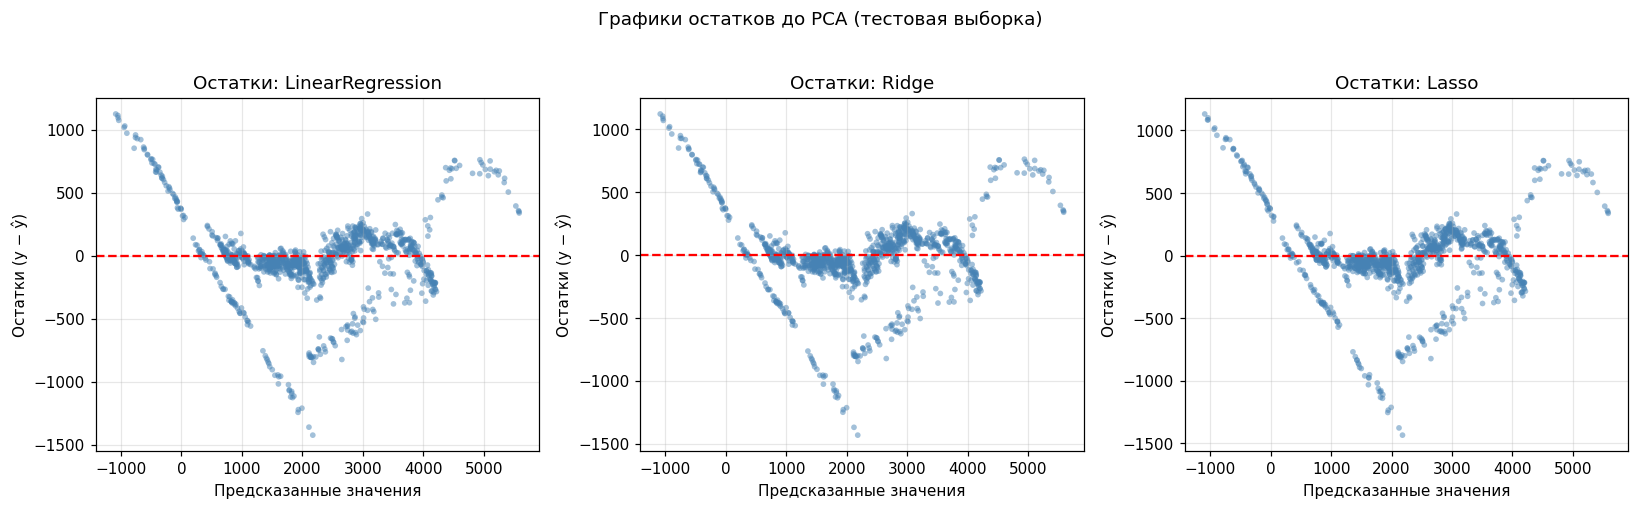

*Рисунок 12. Остатки моделей до PCA*

На графиках «предсказание vs остаток» проведена **горизонтальная линия на уровне 0**. Остатки **не похожи на случайный шум**: они образуют выраженные кривые и диагональные полосы — это признак нарушения линейности. Причины видны на графиках из раздела 2.5: зависимость продаж от цены разная для разных типов магазинов (взаимодействие `MRP` × тип магазина) и выходит на плато при высоких ценах, а линейная модель с одним общим наклоном этого не передаёт. Следствие — для 55 из 1123 тестовых строк (в основном Grocery Store) модель предсказывает **отрицательные продажи**. Стандартное отклонение остатков по терцилям предсказаний ≈ 345, 289, 264 — разброс неоднороден, то есть имеется и гетероскедастичность. Предположения классической линейной регрессии (линейность и постоянная дисперсия ошибок) здесь выполняются лишь приближённо.

### 4.4. Устранение мультиколлинеарности с помощью PCA

Конвейер: импутация + one-hot → `StandardScaler` → `PCA(n_components=0.95)` → регрессор.

Порог 0.95 — минимальное число компонент, сохраняющих ≥ 95% дисперсии признаков. Стандартизация перед PCA обязательна: иначе компоненты определялись бы признаками с наибольшим масштабом. PCA применяется только к предикторам (target не входит). Компоненты ортогональны, что устраняет мультиколлинеарность.

In [ ]:
searches_after, preds_after, rows_after = {}, {}, []
for name, (est, params) in model_specs.items():
    pipe = Pipeline([
        ("preprocessor", pca_preprocessor),
        ("pca", PCA(n_components=0.95)),
        ("model", est),
    ])
    gs = GridSearchCV(pipe, params, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    pred = gs.predict(X_test)
    pca = gs.best_estimator_.named_steps["pca"]
    searches_after[name] = gs
    preds_after[name] = pred
    m = regression_metrics(y_test, pred)
    rows_after.append({
        "Model": name, **m,
        "Best_CV_RMSE": float(-gs.best_score_),
        "PCA_components": int(pca.n_components_),
        "PCA_explained_variance": float(pca.explained_variance_ratio_.sum()),
        "Best_Params": str(gs.best_params_),
    })

after_results = pd.DataFrame(rows_after)
print("Результаты ПОСЛЕ PCA (тест):")
display(after_results[[
    "Model", "RMSE", "R2", "MAPE_%", "Best_CV_RMSE",
    "PCA_components", "PCA_explained_variance", "Best_Params"
]].round(4))

fitted_pca = searches_after["LinearRegression"].best_estimator_.named_steps["pca"]
ratios = fitted_pca.explained_variance_ratio_
cumulative = ratios.cumsum()
components = list(range(1, len(ratios) + 1))

plt.figure(figsize=(9, 5))
plt.plot(components, ratios, marker="o")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("Scree plot")
plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "scree_plot.png", dpi=110, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(components, cumulative, marker="o")
plt.axhline(0.95, linestyle="--", color="red", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance")
plt.xticks(components)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cumulative_explained_variance.png", dpi=110, bbox_inches="tight")
plt.show()

print(f"Число компонент: {fitted_pca.n_components_}")
print(f"Суммарная дисперсия: {ratios.sum():.6f}")

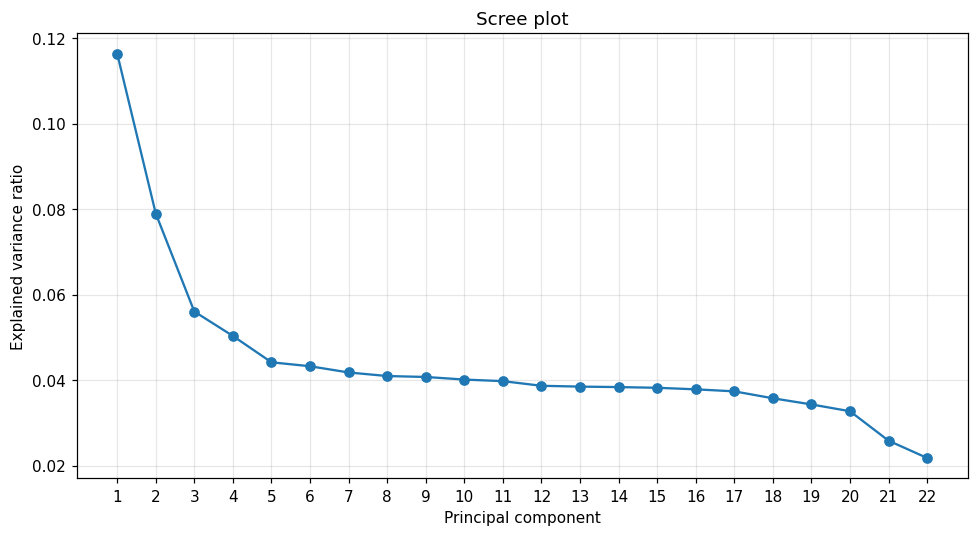

*Рисунок 13. Scree plot (график каменистой осыпи)*

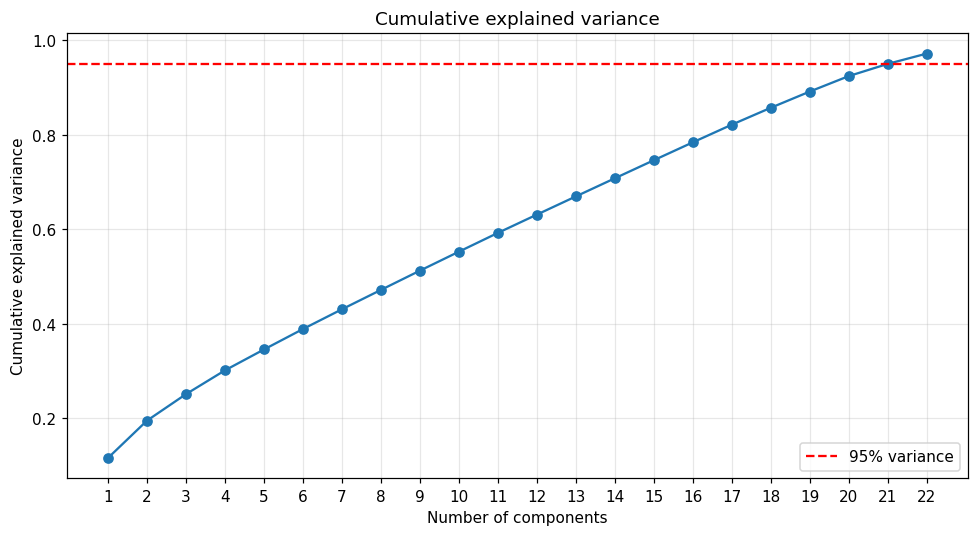

*Рисунок 14. Накопленная объяснённая дисперсия*

Число сохранённых главных компонент — **22 из 27**, суммарно ≈ **97.16%** дисперсии (после 21-й компоненты накоплено ≈ 94.99% < 95%). Первая компонента объясняет ≈ 11.6%, вторая ≈ 7.9%, затем вклад быстро выходит на плато ≈ 3.4–4.3% — так ведут себя почти не коррелирующие между собой one-hot признаки. Резкого «колена» нет, поэтому порог 95% сжимает данные умеренно: отброшено лишь 5 компонент.

In [ ]:
Z_std = build_pca_preprocessor().fit_transform(X_train)
Z = pd.DataFrame(
    PCA(n_components=fitted_pca.n_components_).fit_transform(Z_std),
    columns=[f"PC{i + 1}" for i in range(fitted_pca.n_components_)],
)
vif_pca = calc_vif(Z)
print("Максимальный VIF до PCA (вся матрица признаков):", round(vif_df["VIF"].max(), 2))
print("Максимальный VIF главных компонент:             ", round(vif_pca["VIF"].max(), 4))
display(vif_pca.round(4))

Проверка: максимальный VIF главных компонент ≈ 1.00 (против 102 у исходных признаков). Все VIF равны 1 — компоненты ортогональны, **мультиколлинеарность устранена полностью**.

**Результаты после PCA (компонент: 22, тестовая выборка):**

| Model | RMSE | R² | MAPE_% | Best_CV_RMSE |
|:---|---:|---:|---:|---:|
| LinearRegression | ≈ 794.8 | ≈ 0.6013 | ≈ 73.5 | ≈ 760.0 |
| Ridge | ≈ 794.7 | ≈ 0.6014 | ≈ 73.5 | ≈ 760.0 |
| Lasso | ≈ 794.6 | ≈ 0.6015 | ≈ 73.6 | ≈ 760.0 |

### 4.5. Остатки после PCA

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, pred) in zip(axes, preds_after.items()):
    residuals = y_test.values - pred
    ax.scatter(pred, residuals, alpha=0.5, s=14, edgecolors="none", color="darkorange")
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_xlabel("Предсказанные значения")
    ax.set_ylabel("Остатки (y − ŷ)")
    ax.set_title(f"Остатки после PCA: {name}")
plt.suptitle("Графики остатков после PCA", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "residuals_after_pca.png", dpi=110, bbox_inches="tight")
plt.show()

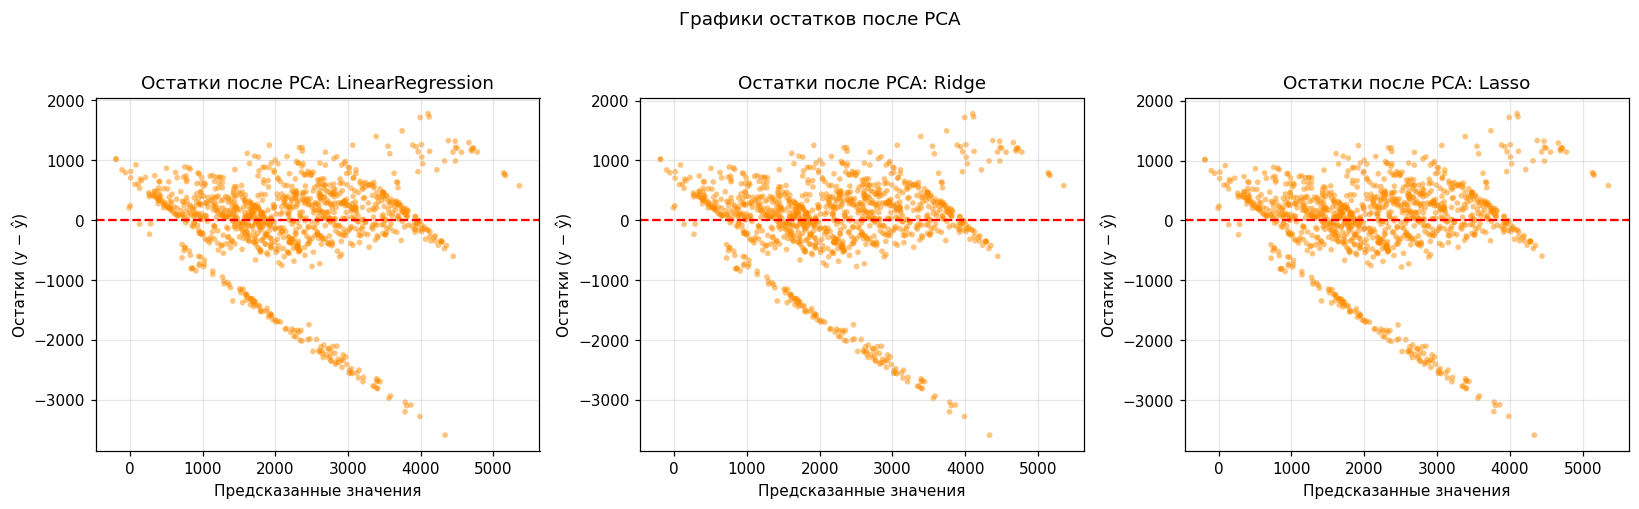

*Рисунок 15. Остатки моделей после PCA*

После PCA облако остатков заметно шире, а ниже основной массы появляется отдельная диагональная полоса больших отрицательных остатков (до ≈ −3500). Среди строк с остатком меньше −1000 доля Grocery Store составляет 100% (из 115 строк): модель после PCA перестаёт отличать продовольственные магазины от супермаркетов и завышает их продажи. Это согласуется с резким ростом RMSE.

### 4.6. Сравнение метрик до и после PCA

In [ ]:
combined = pd.concat([
    before_results.assign(Stage="Before PCA"),
    after_results.assign(Stage="After PCA"),
], ignore_index=True)
print("Сводная таблица:")
display(combined[[
    "Stage", "Model", "RMSE", "R2", "MAPE_%", "Best_CV_RMSE",
    "PCA_components", "PCA_explained_variance"
]].round(4))

models = list(before_results["Model"])
x = np.arange(len(models))
width = 0.35

for metric, label, fname in [("RMSE", "RMSE", "rmse"), ("R2", "R²", "r2"), ("MAPE_%", "MAPE, %", "mape")]:
    plt.figure(figsize=(10, 6))
    plt.bar(x - width / 2, before_results[metric], width, label="Before PCA")
    plt.bar(x + width / 2, after_results[metric], width, label="After PCA")
    plt.xticks(x, models)
    plt.ylabel(label)
    plt.title(f"{label} comparison before and after PCA")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{fname}_before_after_pca.png", dpi=110, bbox_inches="tight")
    plt.show()

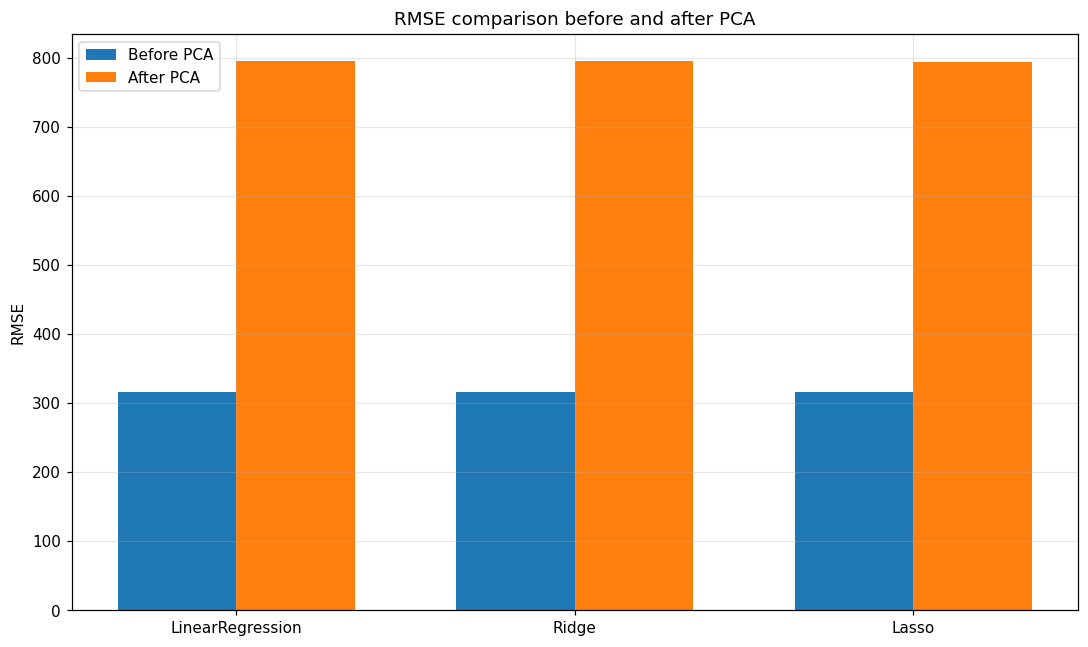

*Рисунок 16. Сравнение RMSE до и после PCA*

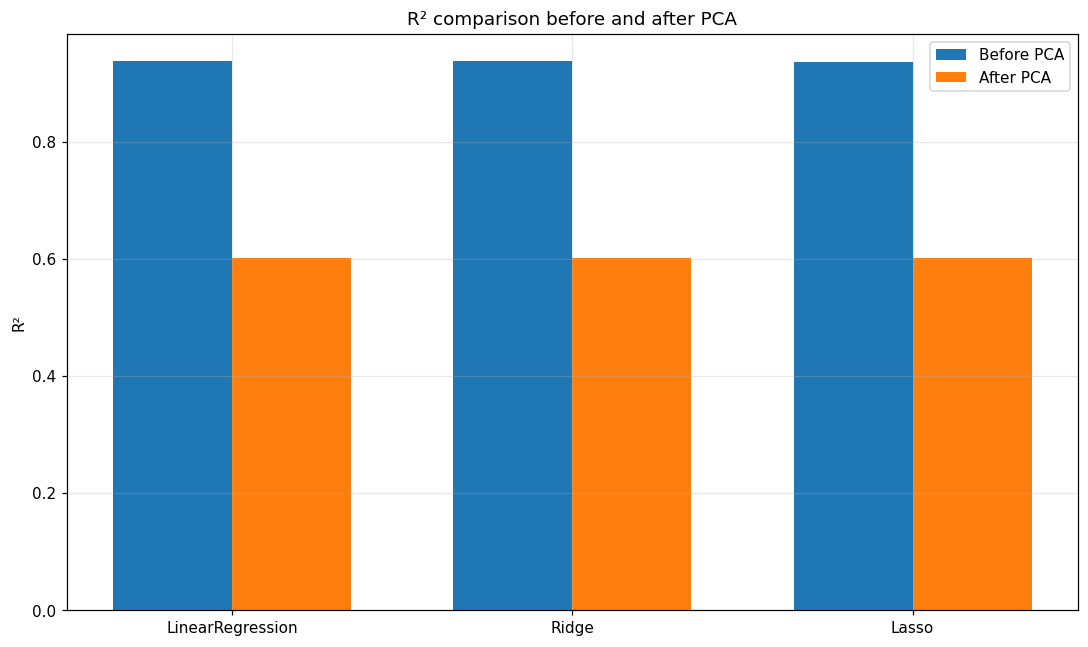

*Рисунок 17. Сравнение R² до и после PCA*

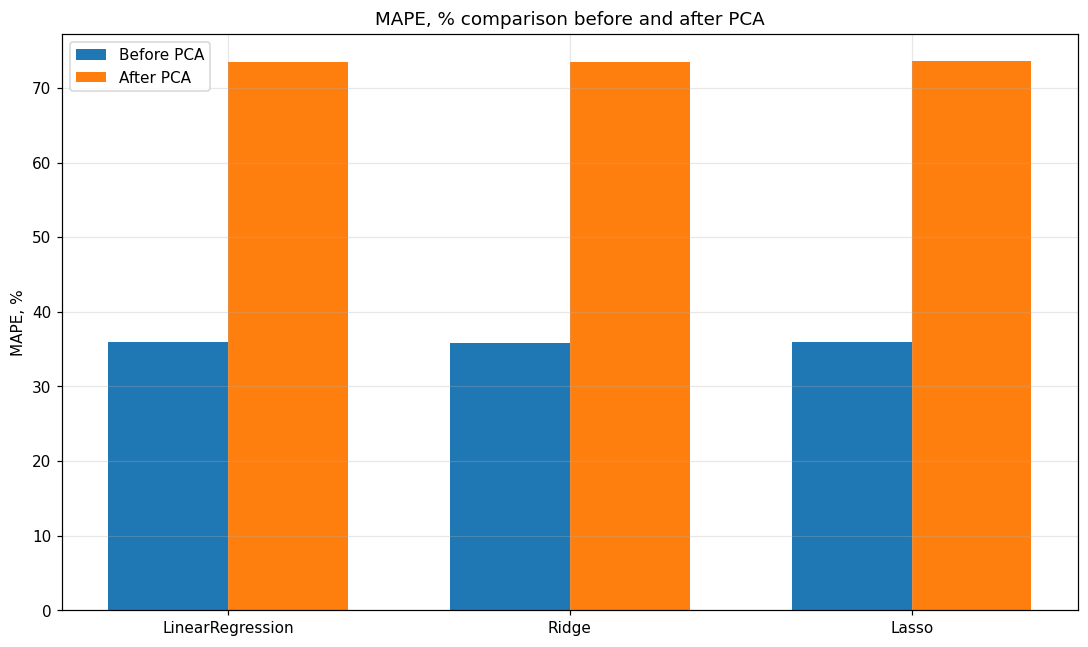

*Рисунок 18. Сравнение MAPE до и после PCA*

**Изменение метрик после PCA:**

| Model | ΔRMSE, % | ΔR² | ΔMAPE, п.п. |
|:---|---:|---:|---:|
| LinearRegression | +152.0 | -0.336 | +37.6 |
| Ridge | +151.9 | -0.336 | +37.7 |
| Lasso | +151.5 | -0.335 | +37.6 |

После PCA для всех моделей:
- RMSE вырос (≈ 316 → ≈ 795, в 2.5 раза);
- $R^2$ снизился (≈ 0.937 → ≈ 0.601);
- MAPE вырос (≈ 36% → ≈ 74%).

Различия между Linear / Ridge / Lasso ничтожны по сравнению с разницей «до vs после PCA». Несмотря на то, что сохранено ≈ 97% дисперсии признаков, качество упало сильно. Причину проверяет следующий пункт.

### 4.7. Почему PCA ухудшил качество: зависимость $R^2$ от числа компонент

In [ ]:
n_max = X_design.shape[1]
rows = []
for k in range(1, n_max + 1):
    pipe = Pipeline([
        ("preprocessor", build_pca_preprocessor()),
        ("pca", PCA(n_components=k)),
        ("model", LinearRegression()),
    ])
    pipe.fit(X_train, y_train)
    rows.append({"k": k, "R2": r2_score(y_test, pipe.predict(X_test))})
sens = pd.DataFrame(rows)
display(sens.round(4).T)

plt.figure(figsize=(10, 5))
plt.plot(sens["k"], sens["R2"], marker="o")
plt.axvline(fitted_pca.n_components_, color="red", linestyle="--",
            label=f"выбрано по порогу 95%: {fitted_pca.n_components_}")
plt.axhline(before_results.loc[0, "R2"], color="green", linestyle=":", label="без PCA")
plt.xlabel("Число главных компонент")
plt.ylabel("R² на тесте (Linear Regression)")
plt.title("Качество модели в зависимости от числа компонент")
plt.xticks(sens["k"])
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "r2_vs_components.png", dpi=110, bbox_inches="tight")
plt.show()

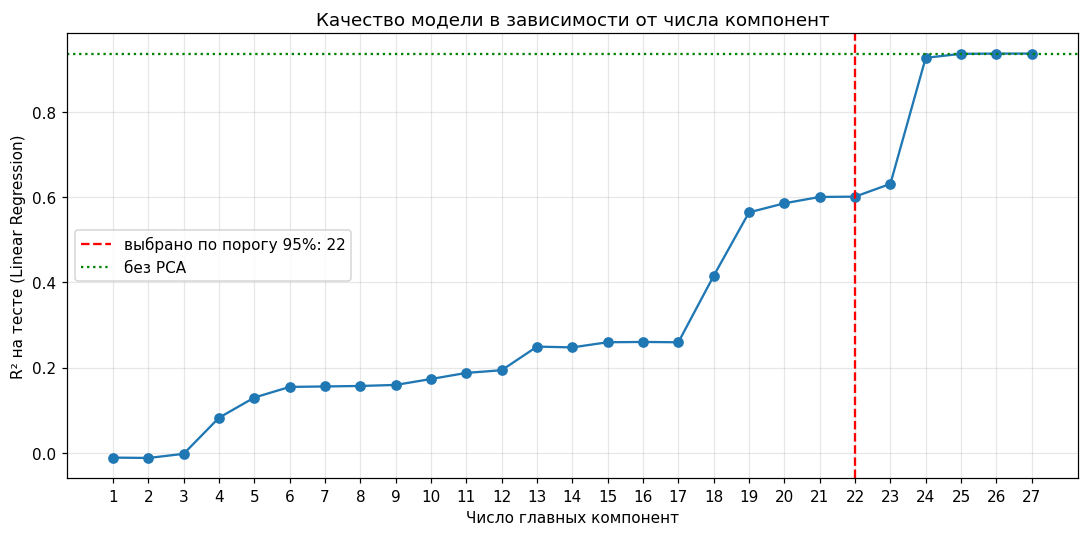

*Рисунок 19. Качество Linear Regression в зависимости от числа компонент*

На графике видно, что $R^2$ растёт ступенями: при 22 компонентах (выбор по порогу 95%) он ≈ 0.60, при 23 компонентах ≈ 0.63, а при 24 компонентах резко поднимается до ≈ 0.93 и затем достигает уровня модели без PCA (≈ 0.937). Выбранные порогом 95% компоненты находятся **до** этого скачка.

Объяснение: тип магазина — главный фактор продаж, но четыре признака, описывающие магазин, почти дублируют друг друга (раздел 4.1). Сочетания этих признаков, которые различают магазины, имеют малую дисперсию и оказываются в хвосте списка компонент. PCA отбирает компоненты по дисперсии признаков, а не по связи с целевой переменной, поэтому такие компоненты отбрасываются, а вместе с ними теряется основная информация о продажах. Чтобы PCA здесь не ухудшал качество, нужно сохранить не менее 24 компонент из 27, то есть почти без сжатия.

## 5. Заключение

1. На данных Big Mart построена регрессия продаж по 4 числовым и 5 категориальным признакам (5613 наблюдений после очистки). Целевой столбец взят из файла `Submission.csv`, поэтому метрики показывают, насколько хорошо линейная модель восстанавливает эти значения, а не качество прогноза фактических продаж.
2. Самая сильная связь продаж с признаками — цена `MRP` (r ≈ 0.71) и тип магазина (средние продажи различаются от ≈ 410 до ≈ 3720). Вес товара продажи практически не объясняет.
3. Среди числовых признаков мультиколлинеарности нет (VIF ≈ 1), но во всей матрице с one-hot признаками **VIF ≥ 10 у 7 признаков** (максимум ≈ 102): размер, тип города, тип магазина и год открытия дублируют друг друга, так как магазинов всего 10.
4. Linear Regression, Ridge и Lasso на исходных признаках дают одинаковое качество: **RMSE ≈ 316, $R^2$ ≈ 0.94, MAPE ≈ 36%**. Высокий MAPE объясняется малыми значениями продаж в Grocery Store. Остатки имеют выраженную нелинейную структуру, а для части строк модель даёт отрицательные продажи: линейная модель не передаёт различие наклонов по типам магазинов и плато при высоких ценах.
5. PCA (оставлено 22 из 27 компонент, ≈ 97.2% дисперсии) полностью устраняет мультиколлинеарность (все VIF = 1), но **сильно ухудшает** качество: RMSE ≈ 795, $R^2$ ≈ 0.60, MAPE ≈ 74%. Анализ зависимости $R^2$ от числа компонент (п. 4.7) показал причину: информация о типе магазина лежит в компонентах с малой дисперсией, которые порог 95% отбрасывает.
6. **Вывод:** для прогноза продаж в данной постановке следует использовать исходные признаки с Ridge или Linear Regression; PCA с порогом 95% применять нельзя. Если PCA всё же нужен, число компонент выбирают по качеству на кросс-валидации, а не только по доле объяснённой дисперсии.

Возможные улучшения: добавление взаимодействий (`MRP` × тип магазина), так как наклон зависимости продаж от цены различается по магазинам; логарифмирование продаж для устранения гетероскедастичности; нелинейные модели (градиентный бустинг); использование обучающего файла с фактическими продажами.

## 6. Список источников

1. Hastie T., Tibshirani R., Friedman J. *The Elements of Statistical Learning*. Springer.
2. James G., Witten D., Hastie T., Tibshirani R. *An Introduction to Statistical Learning*. Springer.
3. Документация scikit-learn: Linear Models, PCA, Pipeline, GridSearchCV. https://scikit-learn.org/
4. Belsley D. A., Kuh E., Welsch R. E. *Regression Diagnostics: Identifying Influential Data and Sources of Collinearity*. Wiley (VIF и мультиколлинеарность).
5. Pedregosa et al. Scikit-learn: Machine Learning in Python. *JMLR*, 2011.
6. Analytics Vidhya. Practice Problem: Big Mart Sales III. https://datahack.analyticsvidhya.com/contest/practice-problem-big-mart-sales-iii/

## 7. Приложение. Полный листинг программного кода

Ниже — объединённый самодостаточный скрипт, воспроизводящий все шаги лабораторной работы. Для интерактивного разбора используйте ячейки выше; этот блок предназначен для отчёта и повторного запуска целиком (его можно сохранить как `lab1_sales.py` и запустить командой `python lab1_sales.py`).

In [ ]:
# =============================================================================
# ПРИЛОЖЕНИЕ: полный листинг кода
# Лабораторная работа: Linear / Ridge / Lasso + PCA (Big Mart Sales, вариант 5)
# Запуск: python lab1_sales.py  (рядом должны лежать Test-Set.csv и Submission.csv;
# нужны numpy, pandas, matplotlib, scikit-learn)
# =============================================================================

from __future__ import annotations
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

RANDOM_STATE = 42
TARGET = "Item_Outlet_Sales"
NUMERIC_FEATURES = ["Weight", "ProductVisibility", "MRP", "EstablishmentYear"]
CATEGORICAL_FEATURES = ["FatContent", "ProductType", "OutletSize", "LocationType", "OutletType"]
FEATURES_FILE = "Test-Set.csv"      # признаки товаров и магазинов (Big Mart)
SALES_FILE = "Submission.csv"       # значения Item_Outlet_Sales для этих же строк
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Библиотеки загружены.")

def find_file(name: str) -> Path | None:
    for p in (Path(name), Path("data") / name, Path("/content") / name):
        if p.exists():
            return p
    return None


missing = [n for n in (FEATURES_FILE, SALES_FILE) if find_file(n) is None]
if missing:  # в Colab предлагаем загрузить файлы вручную
    try:
        from google.colab import files
        print("Загрузите файлы:", missing)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Положите файлы {missing} рядом с ноутбуком")

features = pd.read_csv(find_file(FEATURES_FILE))
sales = pd.read_csv(find_file(SALES_FILE))

# строки двух файлов идут в одном порядке: проверяем совпадение идентификаторов
assert (features["ProductID"].values == sales["Item_Identifier"].values).all()
assert (features["OutletID"].values == sales["Outlet_Identifier"].values).all()
df = features.assign(**{TARGET: sales[TARGET].values})

print("Форма:", df.shape)
print("\nТипы:\n", df.dtypes)
print("\nПропуски:\n", df.isna().sum())
print(df.head())
print(df.describe())
for col in CATEGORICAL_FEATURES:
    print(f"\n{col}:\n", df[col].value_counts(dropna=False))

df_clean = df.copy()

# 1. Приводим к единому виду написания жирности (LF / low fat / reg)
df_clean["FatContent"] = df_clean["FatContent"].replace(
    {"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"}
)
# 2. Нулевая видимость товара на полке невозможна -> считаем пропуском
n_zero_vis = int((df_clean["ProductVisibility"] == 0).sum())
df_clean["ProductVisibility"] = df_clean["ProductVisibility"].replace(0, np.nan)
# 3. Продажи не могут быть отрицательными/нулевыми: такие строки удаляем
n_bad_target = int((df_clean[TARGET] <= 0).sum())
df_clean = df_clean[df_clean[TARGET] > 0].reset_index(drop=True)

print("FatContent после очистки:\n", df_clean["FatContent"].value_counts())
print(f"\nНулевая видимость заменена на пропуск: {n_zero_vis} строк")
print(f"Удалено строк с продажами <= 0: {n_bad_target}")
print(f"Осталось наблюдений: {len(df_clean)} (было {len(df)})")

for col in NUMERIC_FEATURES + [TARGET]:
    plt.figure(figsize=(7, 5))
    plt.hist(df_clean[col].dropna(), bins=25, edgecolor="black", alpha=0.75, color="steelblue")
    plt.xlabel(col)
    plt.ylabel("Частота")
    plt.title(f"Distribution: {col}")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"distribution_{col}.png", dpi=110, bbox_inches="tight")
    plt.close()

plt.figure(figsize=(9, 5))
labels = sorted(df_clean["OutletType"].unique())
groups = [df_clean.loc[df_clean["OutletType"] == t, TARGET].values for t in labels]
plt.boxplot(groups)
plt.xticks(range(1, len(labels) + 1), labels, rotation=10)
plt.xlabel("OutletType")
plt.ylabel(TARGET)
plt.title("Sales by outlet type")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "sales_by_outlet_type.png", dpi=110, bbox_inches="tight")
plt.close()

for col in ["MRP", "ProductVisibility", "Weight"]:
    plt.figure(figsize=(7, 5))
    for outlet_type in sorted(df_clean["OutletType"].unique()):
        subset = df_clean[df_clean["OutletType"] == outlet_type]
        plt.scatter(subset[col], subset[TARGET], label=outlet_type, alpha=0.5, s=12)
    plt.xlabel(col)
    plt.ylabel(TARGET)
    plt.title(f"Sales vs {col}")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"scatter_sales_vs_{col}.png", dpi=110, bbox_inches="tight")
    plt.close()

corr = df_clean[NUMERIC_FEATURES + [TARGET]].corr()
print(corr.round(4))
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap="RdYlGn", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im, ax=ax, fraction=0.046)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=10)
ax.grid(False)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_matrix.png", dpi=110, bbox_inches="tight")
plt.close()

X = df_clean[NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
y = df_clean[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

def build_model_preprocessor() -> ColumnTransformer:
    """Числовые: median + StandardScaler; категориальные: mode + OneHot(drop first)."""
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, NUMERIC_FEATURES),
            ("cat", categorical_pipe, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        sparse_threshold=0,
    )

def build_pca_preprocessor() -> Pipeline:
    """Для PCA: импутация + one-hot, затем StandardScaler на всей матрице."""
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    ct = ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, NUMERIC_FEATURES),
            ("cat", categorical_pipe, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        sparse_threshold=0,
    )
    return Pipeline([("columns", ct), ("scaler", StandardScaler())])

model_preprocessor = build_model_preprocessor()
pca_preprocessor = build_pca_preprocessor()
print("Препроцессоры созданы.")

def calc_vif(frame: pd.DataFrame) -> pd.DataFrame:
    """VIF_j = 1 / (1 - R_j^2): R_j^2 - детерминация регрессии признака j на все остальные."""
    rows = []
    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        rows.append({"Feature": col, "VIF": 1.0 / max(1.0 - r2, 1e-12)})
    return pd.DataFrame(rows)

# (а) только числовые признаки (после импутации медианой), только train
X_num = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train[NUMERIC_FEATURES]),
    columns=NUMERIC_FEATURES,
)
vif_num = calc_vif(X_num)
print("VIF числовых признаков:")
print(vif_num.round(3))

# (б) вся матрица признаков: числовые + one-hot категориальные
vif_prep = build_pca_preprocessor().fit(X_train)
X_design = pd.DataFrame(
    vif_prep.transform(X_train),
    columns=[n.split("__", 1)[1] for n in vif_prep.named_steps["columns"].get_feature_names_out()],
)
vif_df = calc_vif(X_design).sort_values("VIF", ascending=False).reset_index(drop=True)
print("VIF всей матрицы признаков (топ-12):")
print(vif_df.head(12).round(3))

plt.figure(figsize=(8, 8))
plot_df = vif_df.sort_values("VIF")
plt.barh(plot_df["Feature"], plot_df["VIF"], color="steelblue")
plt.xlabel("VIF")
plt.title("Variance Inflation Factor (VIF), вся матрица признаков")
plt.axvline(10, color="red", linestyle="--", label="порог 10")
plt.axvline(5, color="orange", linestyle="--", label="порог 5")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "vif.png", dpi=110, bbox_inches="tight")
plt.close()

def mape(y_true, y_pred) -> float:
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    non_zero = y_true != 0
    return float(np.mean(np.abs((y_true[non_zero] - y_pred[non_zero]) / y_true[non_zero])) * 100)

def regression_metrics(y_true, y_pred) -> dict:
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "MAPE_%": mape(y_true, y_pred),
    }

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_specs = {
    "LinearRegression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-3, 3, 13)}),
    "Lasso": (Lasso(max_iter=100_000), {"model__alpha": np.logspace(-3, 1, 12)}),
}

searches_before, preds_before, rows_before = {}, {}, []
for name, (est, params) in model_specs.items():
    pipe = Pipeline([
        ("preprocessor", clone(model_preprocessor)),
        ("model", est),
    ])
    gs = GridSearchCV(pipe, params, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    pred = gs.predict(X_test)
    searches_before[name] = gs
    preds_before[name] = pred
    m = regression_metrics(y_test, pred)
    rows_before.append({
        "Model": name, **m,
        "Best_CV_RMSE": float(-gs.best_score_),
        "Best_Params": str(gs.best_params_),
    })

before_results = pd.DataFrame(rows_before)
print("Результаты ДО PCA (тест):")
print(before_results[["Model", "RMSE", "R2", "MAPE_%", "Best_CV_RMSE", "Best_Params"]].round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, pred) in zip(axes, preds_before.items()):
    residuals = y_test.values - pred
    ax.scatter(pred, residuals, alpha=0.5, s=14, edgecolors="none", color="steelblue")
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_xlabel("Предсказанные значения")
    ax.set_ylabel("Остатки (y − ŷ)")
    ax.set_title(f"Остатки: {name}")
plt.suptitle("Графики остатков до PCA (тестовая выборка)", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "residuals_before_pca.png", dpi=110, bbox_inches="tight")
plt.close()

for name, pred in preds_before.items():
    residuals = y_test.values - pred
    q = np.quantile(pred, [1/3, 2/3])
    groups = [
        residuals[pred <= q[0]],
        residuals[(pred > q[0]) & (pred <= q[1])],
        residuals[pred > q[1]],
    ]
    stds = [np.std(g) for g in groups if len(g) > 1]
    print(f"{name}: ст. откл. остатков по терцилям = {[round(float(s), 1) for s in stds]}")

searches_after, preds_after, rows_after = {}, {}, []
for name, (est, params) in model_specs.items():
    pipe = Pipeline([
        ("preprocessor", pca_preprocessor),
        ("pca", PCA(n_components=0.95)),
        ("model", est),
    ])
    gs = GridSearchCV(pipe, params, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    pred = gs.predict(X_test)
    pca = gs.best_estimator_.named_steps["pca"]
    searches_after[name] = gs
    preds_after[name] = pred
    m = regression_metrics(y_test, pred)
    rows_after.append({
        "Model": name, **m,
        "Best_CV_RMSE": float(-gs.best_score_),
        "PCA_components": int(pca.n_components_),
        "PCA_explained_variance": float(pca.explained_variance_ratio_.sum()),
        "Best_Params": str(gs.best_params_),
    })

after_results = pd.DataFrame(rows_after)
print("Результаты ПОСЛЕ PCA (тест):")
print(after_results[[
    "Model", "RMSE", "R2", "MAPE_%", "Best_CV_RMSE",
    "PCA_components", "PCA_explained_variance", "Best_Params"
]].round(4))

fitted_pca = searches_after["LinearRegression"].best_estimator_.named_steps["pca"]
ratios = fitted_pca.explained_variance_ratio_
cumulative = ratios.cumsum()
components = list(range(1, len(ratios) + 1))

plt.figure(figsize=(9, 5))
plt.plot(components, ratios, marker="o")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("Scree plot")
plt.xticks(components)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "scree_plot.png", dpi=110, bbox_inches="tight")
plt.close()

plt.figure(figsize=(9, 5))
plt.plot(components, cumulative, marker="o")
plt.axhline(0.95, linestyle="--", color="red", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance")
plt.xticks(components)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cumulative_explained_variance.png", dpi=110, bbox_inches="tight")
plt.close()

print(f"Число компонент: {fitted_pca.n_components_}")
print(f"Суммарная дисперсия: {ratios.sum():.6f}")

Z_std = build_pca_preprocessor().fit_transform(X_train)
Z = pd.DataFrame(
    PCA(n_components=fitted_pca.n_components_).fit_transform(Z_std),
    columns=[f"PC{i + 1}" for i in range(fitted_pca.n_components_)],
)
vif_pca = calc_vif(Z)
print("Максимальный VIF до PCA (вся матрица признаков):", round(vif_df["VIF"].max(), 2))
print("Максимальный VIF главных компонент:             ", round(vif_pca["VIF"].max(), 4))
print(vif_pca.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, pred) in zip(axes, preds_after.items()):
    residuals = y_test.values - pred
    ax.scatter(pred, residuals, alpha=0.5, s=14, edgecolors="none", color="darkorange")
    ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
    ax.set_xlabel("Предсказанные значения")
    ax.set_ylabel("Остатки (y − ŷ)")
    ax.set_title(f"Остатки после PCA: {name}")
plt.suptitle("Графики остатков после PCA", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "residuals_after_pca.png", dpi=110, bbox_inches="tight")
plt.close()

combined = pd.concat([
    before_results.assign(Stage="Before PCA"),
    after_results.assign(Stage="After PCA"),
], ignore_index=True)
print("Сводная таблица:")
print(combined[[
    "Stage", "Model", "RMSE", "R2", "MAPE_%", "Best_CV_RMSE",
    "PCA_components", "PCA_explained_variance"
]].round(4))

models = list(before_results["Model"])
x = np.arange(len(models))
width = 0.35

for metric, label, fname in [("RMSE", "RMSE", "rmse"), ("R2", "R²", "r2"), ("MAPE_%", "MAPE, %", "mape")]:
    plt.figure(figsize=(10, 6))
    plt.bar(x - width / 2, before_results[metric], width, label="Before PCA")
    plt.bar(x + width / 2, after_results[metric], width, label="After PCA")
    plt.xticks(x, models)
    plt.ylabel(label)
    plt.title(f"{label} comparison before and after PCA")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{fname}_before_after_pca.png", dpi=110, bbox_inches="tight")
    plt.close()

n_max = X_design.shape[1]
rows = []
for k in range(1, n_max + 1):
    pipe = Pipeline([
        ("preprocessor", build_pca_preprocessor()),
        ("pca", PCA(n_components=k)),
        ("model", LinearRegression()),
    ])
    pipe.fit(X_train, y_train)
    rows.append({"k": k, "R2": r2_score(y_test, pipe.predict(X_test))})
sens = pd.DataFrame(rows)
print(sens.round(4).T)

plt.figure(figsize=(10, 5))
plt.plot(sens["k"], sens["R2"], marker="o")
plt.axvline(fitted_pca.n_components_, color="red", linestyle="--",
            label=f"выбрано по порогу 95%: {fitted_pca.n_components_}")
plt.axhline(before_results.loc[0, "R2"], color="green", linestyle=":", label="без PCA")
plt.xlabel("Число главных компонент")
plt.ylabel("R² на тесте (Linear Regression)")
plt.title("Качество модели в зависимости от числа компонент")
plt.xticks(sens["k"])
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "r2_vs_components.png", dpi=110, bbox_inches="tight")
plt.close()

print("\nГотово. Графики сохранены в:", FIGURES_DIR.resolve())